In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.applications import MobileNetV2
from keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

In [3]:
train_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_gen = ImageDataGenerator(rescale=1./255)

train_data = train_gen.flow_from_directory(
    r"C:\Users\m8494\Downloads\Project dataset\train",
    target_size=(224, 224),
    batch_size=16,
    class_mode='categorical'
)

val_data = val_gen.flow_from_directory(
    r"C:\Users\m8494\Downloads\Project dataset\val",
    target_size=(224, 224),
    batch_size=16,
    class_mode='categorical'
)

Found 300 images belonging to 3 classes.
Found 300 images belonging to 3 classes.


In [4]:
base = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)
base.trainable = False

In [5]:
x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dropout(0.3)(x)
out = layers.Dense(3, activation='softmax')(x)

model = models.Model(inputs=base.input, outputs=out)

In [6]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=12
)

Epoch 1/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 139s 7s/step - accuracy: 0.2900 - loss: 1.7379 - val_accuracy: 0.2900 - val_loss: 1.4234
Epoch 2/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 107s 6s/step - accuracy: 0.3100 - loss: 1.4493 - val_accuracy: 0.2933 - val_loss: 1.2554
Epoch 3/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 116s 6s/step - accuracy: 0.3133 - loss: 1.3794 - val_accuracy: 0.3300 - val_loss: 1.1918
Epoch 4/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 118s 6s/step - accuracy: 0.3367 - loss: 1.3172 - val_accuracy: 0.3533 - val_loss: 1.1512
Epoch 5/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 109s 6s/step - accuracy: 0.3933 - loss: 1.2644 - val_accuracy: 0.3700 - val_loss: 1.1187
Epoch 6/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 107s 6s/step - accuracy: 0.4100 - loss: 1.2472 - val_accuracy: 0.4033 - val_loss: 1.0843
Epoch 7/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 109s 6s/step - accuracy: 0.4100 - loss: 1.2197 - val_accuracy: 0.4300 - val_loss: 1.0473
Epoch 8/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 114s 6s/step - accuracy: 0.4200 - loss: 1.1650 - val_accuracy: 0.4533 - v

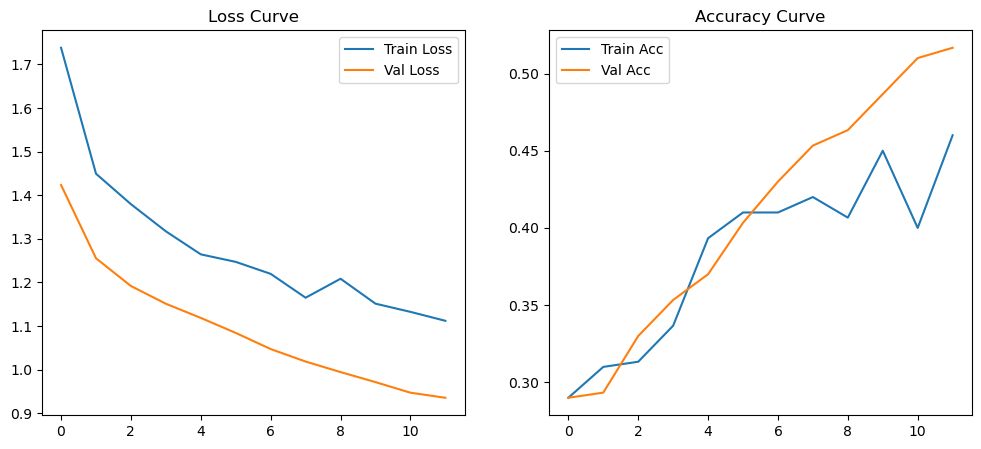

In [8]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss Curve")
plt.legend(['Train Loss', 'Val Loss'])

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy Curve")
plt.legend(['Train Acc', 'Val Acc'])

plt.show()

In [9]:
from keras.preprocessing import image

class_names = list(train_data.class_indices.keys())

def predict(img_path):
    img = image.load_img(img_path, target_size=(224,224))
    x = image.img_to_array(img)/255.0
    x = np.expand_dims(x, axis=0)
    
    preds = model.predict(x)
    cls = np.argmax(preds)
    conf = preds[0][cls]
    
    return class_names[cls], conf

In [10]:
label, confidence = predict("sample.jpg")
print("Predicted:", label)
print("Confidence:", f"{confidence*100:.2f}%")

FileNotFoundError: [Errno 2] No such file or directory: 'sample.jpg'